In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

data_dir = Path(r"C:\Users\Albostan\.gemini\antigravity\scratch")
file_names = {
    "Transactions": "transaction_data.csv",
    "Products": "product.csv",
    "Demographics": "hh_demographic.csv",
    "Causal Data": "causal_data.csv",
    "Campaign Table": "campaign_table.csv",
    "Campaign Desc": "campaign_desc.csv",
    "Coupon": "coupon.csv",
    "Coupon Redemption": "coupon_redempt.csv",
}

tables_preview = {
    table_name: pd.read_csv(data_dir / file_name, nrows=5)
    for table_name, file_name in file_names.items()
}

for table_name, table_data in tables_preview.items():
    print(f"Table: {table_name}")
    display(table_data)

Table: Transactions


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0,0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0,0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0,0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0,0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0,0


Table: Products


,PRODUCT_ID,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
0,25671,2,GROCERY,National,FRZN ICE,ICE - CRUSHED/CUBED,22 LB
1,26081,2,MISC. TRANS.,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION,
2,26093,69,PASTRY,Private,BREAD,BREAD:ITALIAN/FRENCH,
3,26190,69,GROCERY,Private,FRUIT - SHELF STABLE,APPLE SAUCE,50 OZ
4,26355,69,GROCERY,Private,COOKIES/CONES,SPECIALTY COOKIES,14 OZ


Table: Demographics


,AGE_DESC,MARITAL_STATUS_CODE,INCOME_DESC,HOMEOWNER_DESC,HH_COMP_DESC,HOUSEHOLD_SIZE_DESC,KID_CATEGORY_DESC,household_key
0,65+,A,35-49K,Homeowner,2 Adults No Kids,2,None/Unknown,1
1,45-54,A,50-74K,Homeowner,2 Adults No Kids,2,None/Unknown,7
2,25-34,U,25-34K,Unknown,2 Adults Kids,3,1,8
3,25-34,U,75-99K,Homeowner,2 Adults Kids,4,2,13
4,45-54,B,50-74K,Homeowner,Single Female,1,None/Unknown,16


... (6 outputs left out)

Table: Coupon


,COUPON_UPC,PRODUCT_ID,CAMPAIGN
0,10000089061,27160,4
1,10000089064,27754,9
2,10000089073,28897,12
3,51800009050,28919,28
4,52100000076,28929,25


Table: Coupon Redemption


,household_key,DAY,COUPON_UPC,CAMPAIGN
0,1,421,10000085364,8
1,1,421,51700010076,8
2,1,427,54200000033,8
3,1,597,10000085476,18
4,1,597,54200029176,18


In [2]:
import duckdb
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
GAP = 28
TARGET = "banana_next_28d"
FEATURES = [
    "baskets_4w",
    "baskets_8w",
    "spend_4w",
    "spend_8w",
    "avg_basket_value_8w",
    "spend_trend",
    "days_since_last_purchase",
    "tenure_days",
    "banana_days_4w",
    "banana_days_8w",
    "banana_days_12w",
    "banana_days_before",
    "days_since_last_banana",
]

df = pd.read_parquet("C:/Users/Albostan/.gemini/antigravity/scratch/model_table.parquet")

df = df.replace([np.inf, -np.inf], np.nan)
df["spend_trend"] = df["spend_trend"].clip(0, 10)
df = df.sort_values(["ref_day", "household_key"]).reset_index(drop=True)

ref_days = np.sort(df["ref_day"].unique())
train_end = ref_days[int(len(ref_days) * 0.60) - 1]
val_end = ref_days[int(len(ref_days) * 0.80) - 1]

train = df[df["ref_day"] <= train_end]
val = df[(df["ref_day"] > train_end + GAP) & (df["ref_day"] <= val_end)]
test = df[df["ref_day"] > val_end + GAP]

print("train_end:", train_end, "val_end:", val_end)
print("train rows:", len(train), "val rows:", len(val), "test rows:", len(test))
print("positive rate train/val/test:",
      round(train[TARGET].mean(), 3),
      round(val[TARGET].mean(), 3),
      round(test[TARGET].mean(), 3))

X_train, y_train = train[FEATURES], train[TARGET].to_numpy()
X_val, y_val = val[FEATURES], val[TARGET].to_numpy()
X_test, y_test = test[FEATURES], test[TARGET].to_numpy()


def top_k_metrics(y, scores, k=0.10):
    n = int(len(y) * k)
    order = np.argsort(-scores, kind="mergesort")[:n]
    true_positives = y[order].sum()
    precision = true_positives / n
    recall = true_positives / y.sum()
    lift = precision / y.mean()
    return precision, recall, lift


def evaluate(y, scores):
    precision, recall, lift = top_k_metrics(y, scores)
    return {
        "pr_auc": average_precision_score(y, scores),
        "roc_auc": roc_auc_score(y, scores),
        "precision_top10": precision,
        "recall_top10": recall,
        "lift_top10": lift,
    }


def rule_scores(frame):
    return {
        "rule_bought_prev_28d": frame["bought_prev_28d"].to_numpy().astype(float),
        "rule_recency_banana": -frame["days_since_last_banana"].fillna(10000).to_numpy(),
    }


dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)

logistic = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=SEED),
).fit(X_train, y_train)

hgb = HistGradientBoostingClassifier(random_state=SEED).fit(X_train, y_train)

models = {"logistic": logistic, "hgb": hgb}


def score_all(frame, X, y):
    rows = {"dummy": evaluate(y, dummy.predict_proba(X)[:, 1])}
    for name, scores in rule_scores(frame).items():
        rows[name] = evaluate(y, scores)
    for name, model in models.items():
        rows[name] = evaluate(y, model.predict_proba(X)[:, 1])
    return pd.DataFrame(rows).T.round(4)


val_results = score_all(val, X_val, y_val)
print(val_results)

best_name = max(models, key=lambda m: val_results.loc[m, "pr_auc"])
best_model = models[best_name]
print("best model on validation:", best_name)

val_scores = best_model.predict_proba(X_val)[:, 1]
threshold = np.quantile(val_scores, 0.90)
val_pred = (val_scores >= threshold).astype(int)
print("threshold (top 10%):", round(threshold, 4))
print(confusion_matrix(y_val, val_pred))

importance = permutation_importance(
    best_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=3,
    random_state=SEED,
    n_jobs=1,
)
importance_table = (
    pd.DataFrame({"feature": FEATURES, "importance": importance.importances_mean})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
print(importance_table)

test_results = score_all(test, X_test, y_test)
print(test_results)

train_end: 434 val_end: 553
train rows: 99890 val rows: 26239 test rows: 28397
positive rate train/val/test: 0.324 0.342 0.338
                      pr_auc  roc_auc  precision_top10  recall_top10  \
dummy                 0.3416   0.5000           0.3275        0.0958   
rule_bought_prev_28d  0.5308   0.7289           0.6008        0.1758   
rule_recency_banana   0.6460   0.8047           0.7327        0.2144   
logistic              0.7723   0.8445           0.9272        0.2713   
hgb                   0.7708   0.8443           0.9211        0.2696   

                      lift_top10  
dummy                     0.9587  
rule_bought_prev_28d      1.7589  
rule_recency_banana       2.1451  
logistic                  2.7143  
hgb                       2.6965  
best model on validation: logistic
threshold (top 10%): 0.9187
[[17085   191]
 [ 6530  2433]]
                     feature  importance
0         banana_days_before    0.187003
1            banana_days_12w    0.038560
2            

In [3]:
df["banana_rate"] = df["banana_days_before"] / df["tenure_days"].clip(lower=1)
FEATURES_RATE = [f for f in FEATURES if f != "banana_days_before"] + ["banana_rate"]


def make_logistic():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=SEED),
    )


def top_k_row(y, scores, ks=(0.10, 0.20, 0.30)):
    out = {}
    base_rate = y.mean()
    for k in ks:
        n = int(len(y) * k)
        order = np.argsort(-scores, kind="mergesort")[:n]
        hits = y[order].sum()
        out[f"precision_top{int(k * 100)}"] = hits / n
        out[f"recall_top{int(k * 100)}"] = hits / y.sum()
        out[f"lift_top{int(k * 100)}"] = (hits / n) / base_rate
    return out


fold_specs = [(0.30, 0.45), (0.45, 0.60), (0.60, 0.75)]
rows = []

for i, (a, b) in enumerate(fold_specs, start=1):
    fold_train_end = ref_days[int(len(ref_days) * a) - 1]
    fold_val_end = ref_days[int(len(ref_days) * b) - 1]
    tr = df[df["ref_day"] <= fold_train_end]
    va = df[(df["ref_day"] > fold_train_end + GAP) & (df["ref_day"] <= fold_val_end)]
    y_tr = tr[TARGET].to_numpy()
    y_va = va[TARGET].to_numpy()

    candidates = {}
    for name, cols in [("logistic_base", FEATURES), ("logistic_rate", FEATURES_RATE)]:
        model = make_logistic().fit(tr[cols], y_tr)
        candidates[name] = model.predict_proba(va[cols])[:, 1]
    candidates["rule_bought_prev_28d"] = va["bought_prev_28d"].to_numpy().astype(float)
    candidates["rule_recency_banana"] = -va["days_since_last_banana"].fillna(10000).to_numpy()

    for name, scores in candidates.items():
        row = {
            "fold": i,
            "model": name,
            "train_rows": len(tr),
            "val_rows": len(va),
            "positive_rate": y_va.mean(),
            "pr_auc": average_precision_score(y_va, scores),
            "roc_auc": roc_auc_score(y_va, scores),
        }
        row.update(top_k_row(y_va, scores))
        rows.append(row)

folds = pd.DataFrame(rows)
print(folds.round(4).to_string(index=False))

stability = (
    folds.groupby("model")["pr_auc"]
    .agg(["mean", "min", "max", "std"])
    .round(4)
    .sort_values("mean", ascending=False)
)
print(stability)

train_mask = df["ref_day"] <= train_end
val_mask = (df["ref_day"] > train_end + GAP) & (df["ref_day"] <= val_end)
rate_fit = make_logistic().fit(df.loc[train_mask, FEATURES_RATE], df.loc[train_mask, TARGET])
rate_scores = rate_fit.predict_proba(df.loc[val_mask, FEATURES_RATE])[:, 1]
print("validation pr_auc with banana_rate:", round(average_precision_score(df.loc[val_mask, TARGET], rate_scores), 4))
print(pd.Series(top_k_row(df.loc[val_mask, TARGET].to_numpy(), rate_scores)).round(4))

 fold                model  train_rows  val_rows  positive_rate  pr_auc  roc_auc  precision_top10  recall_top10  lift_top10  precision_top20  recall_top20  lift_top20  precision_top30  recall_top30  lift_top30
    1        logistic_base       48427     17708         0.3372  0.7517   0.8326           0.9006        0.2670      2.6708           0.7978        0.4731      2.3660           0.7065        0.6285      2.0953
    1        logistic_rate       48427     17708         0.3372  0.7395   0.8208           0.9011        0.2671      2.6725           0.7919        0.4696      2.3484           0.6896        0.6135      2.0450
    1 rule_bought_prev_28d       48427     17708         0.3372  0.5173   0.7179           0.6220        0.1844      1.8447           0.6337        0.3758      1.8794           0.6259        0.5569      1.8563
    1  rule_recency_banana       48427     17708         0.3372  0.6385   0.7971           0.7390        0.2191      2.1916           0.7060        0.4187      

In [4]:
final_model = make_logistic().fit(train[FEATURES], train[TARGET])


def decile_table(frame, scores):
    out = frame[["household_key", "ref_day", TARGET]].copy()
    out["score"] = scores
    out["rank_pct"] = out["score"].rank(method="first", ascending=False) / len(out)
    out["decile"] = np.ceil(out["rank_pct"] * 10).astype(int)
    summary = (
        out.groupby("decile")
        .agg(rows=(TARGET, "size"), actual_rate=(TARGET, "mean"), avg_score=("score", "mean"))
        .round(4)
    )
    return out, summary


val_scored, val_deciles = decile_table(val, final_model.predict_proba(val[FEATURES])[:, 1])
print(val_deciles)

coefficients = pd.Series(
    final_model.named_steps["logisticregression"].coef_[0], index=FEATURES
).sort_values(key=abs, ascending=False)
print(coefficients.round(4))

        rows  actual_rate  avg_score
decile                              
1       2623       0.9272     0.9792
2       2624       0.7111     0.7933
3       2624       0.5400     0.5260
4       2624       0.3807     0.3233
5       2624       0.2912     0.2132
6       2624       0.1944     0.1579
7       2624       0.1418     0.1257
8       2624       0.1025     0.1042
9       2624       0.0808     0.0862
10      2624       0.0465     0.0657
banana_days_before          0.7046
banana_days_12w             0.5498
banana_days_4w              0.3086
banana_days_8w              0.2802
baskets_4w                  0.2131
tenure_days                -0.2092
baskets_8w                 -0.1578
days_since_last_purchase   -0.1451
spend_8w                    0.1316
avg_basket_value_8w         0.1159
days_since_last_banana      0.0423
spend_trend                -0.0162
spend_4w                   -0.0044
dtype: float64


In [5]:
scoring = pd.read_parquet("C:/Users/Albostan/.gemini/antigravity/scratch/scoring_table.parquet")
scoring = scoring.replace([np.inf, -np.inf], np.nan)
scoring["spend_trend"] = scoring["spend_trend"].clip(0, 10)

full_model = make_logistic().fit(df[FEATURES], df[TARGET])
scoring["score"] = full_model.predict_proba(scoring[FEATURES])[:, 1]
scoring["rank_pct"] = scoring["score"].rank(method="first", ascending=False) / len(scoring)
scoring["decile"] = np.ceil(scoring["rank_pct"] * 10).astype(int)

report = scoring[["household_key", "ref_day", "score", "decile", "bought_prev_28d", "days_since_last_banana", "banana_days_before"]]
report = report.sort_values("score", ascending=False).reset_index(drop=True)
report.to_csv("banana_follow_up_list.csv", index=False)

print(report.head(20))
print(report["decile"].value_counts().sort_index())
print(report["score"].describe().round(4))

    household_key  ref_day     score  decile  bought_prev_28d  \
0            1740      711  1.000000       1                1   
1            1609      711  1.000000       1                1   
2            1098      711  0.999999       1                1   
3            2264      711  0.999996       1                1   
4            1029      711  0.999994       1                1   
5            1397      711  0.999994       1                1   
6             219      711  0.999993       1                1   
7            1379      711  0.999992       1                1   
8             389      711  0.999987       1                1   
9             523      711  0.999962       1                0   
10           1879      711  0.999957       1                1   
11            361      711  0.999892       1                1   
12            982      711  0.999804       1                1   
13            712      711  0.999778       1                1   
14            745      71

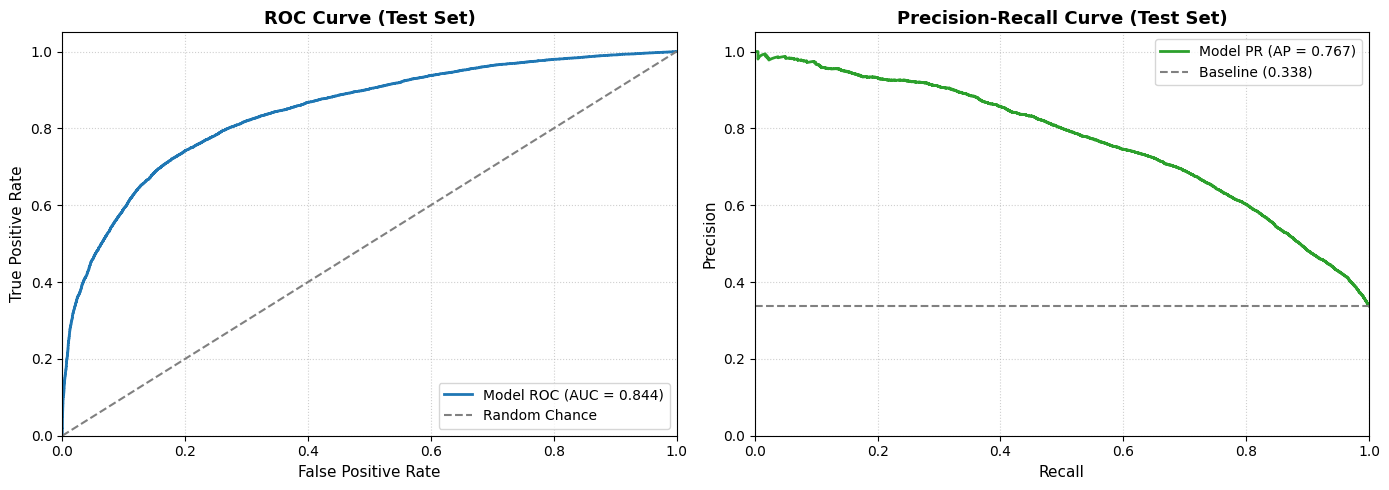

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score

y_scores = final_model.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_scores)
roc_val = auc(fpr, tpr)

prec, rec, _ = precision_recall_curve(y_test, y_scores)
pr_val = average_precision_score(y_test, y_scores)
baseline_pr = y_test.mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr, tpr, color="#1f77b4", lw=2, label=f"Model ROC (AUC = {roc_val:.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random Chance")
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel("False Positive Rate", fontsize=11)
axes[0].set_ylabel("True Positive Rate", fontsize=11)
axes[0].set_title("ROC Curve (Test Set)", fontsize=13, fontweight="bold")
axes[0].legend(loc="lower right")
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].plot(rec, prec, color="#2ca02c", lw=2, label=f"Model PR (AP = {pr_val:.3f})")
axes[1].axhline(baseline_pr, color="gray", linestyle="--", label=f"Baseline ({baseline_pr:.3f})")
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("Recall", fontsize=11)
axes[1].set_ylabel("Precision", fontsize=11)
axes[1].set_title("Precision-Recall Curve (Test Set)", fontsize=13, fontweight="bold")
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

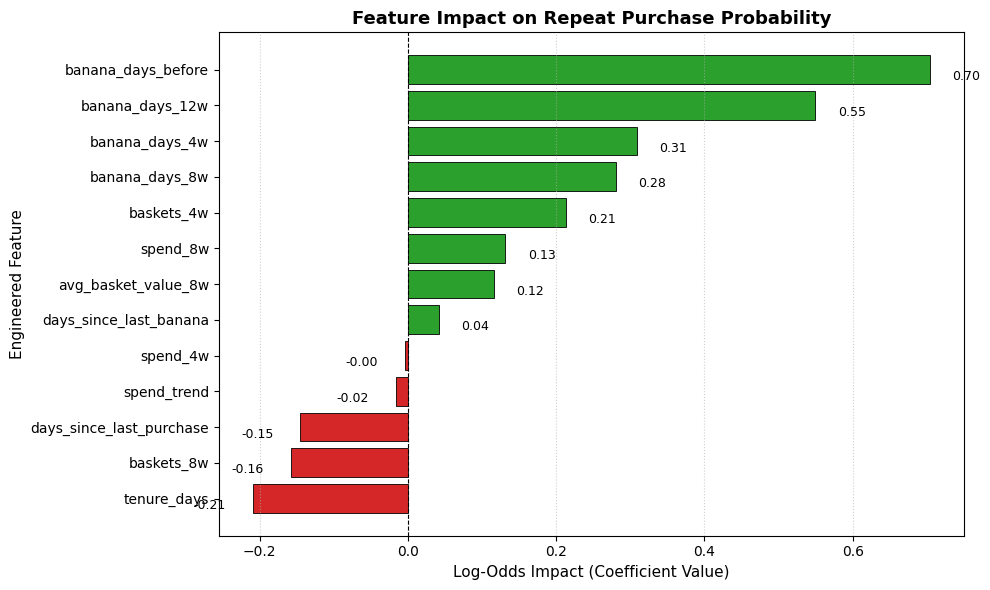

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

coef_df = pd.DataFrame({
    "feature": FEATURES,
    "coefficient": final_model.named_steps["logisticregression"].coef_[0]
}).sort_values("coefficient", ascending=True)

colors = ["#d62728" if c < 0 else "#2ca02c" for c in coef_df["coefficient"]]

plt.figure(figsize=(10, 6))
bars = plt.barh(coef_df["feature"], coef_df["coefficient"], color=colors, edgecolor="black", linewidth=0.6)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.xlabel("Log-Odds Impact (Coefficient Value)", fontsize=11)
plt.ylabel("Engineered Feature", fontsize=11)
plt.title("Feature Impact on Repeat Purchase Probability", fontsize=13, fontweight="bold")
plt.grid(axis="x", linestyle=":", alpha=0.6)

for bar in bars:
    val = bar.get_width()
    offset = 0.03 if val >= 0 else -0.08
    plt.text(val + offset, bar.get_y() + bar.get_height() / 4, f"{val:.2f}", fontsize=9, va="center")

plt.tight_layout()
plt.show()

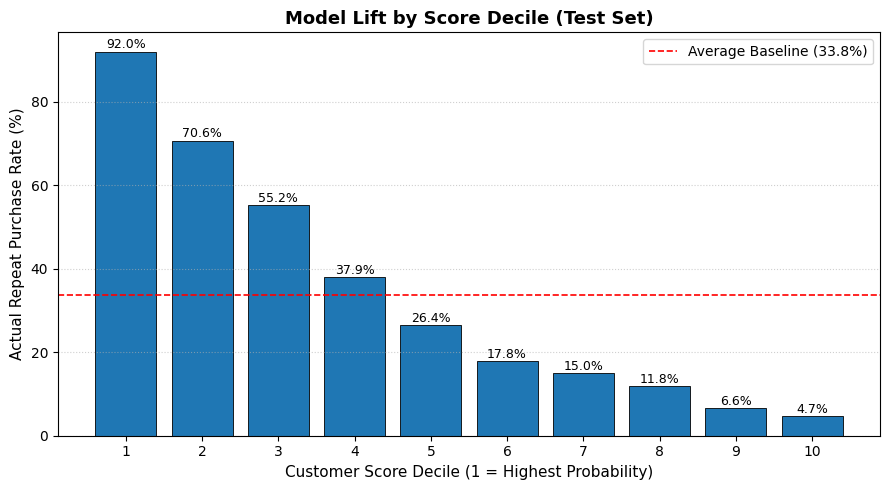

In [8]:
import matplotlib.pyplot as plt

test_scored, test_deciles = decile_table(test, final_model.predict_proba(test[FEATURES])[:, 1])

plt.figure(figsize=(9, 5))
bars = plt.bar(
    test_deciles.index,
    test_deciles["actual_rate"] * 100,
    color="#1f77b4",
    edgecolor="black",
    linewidth=0.6
)
plt.axhline(
    test[TARGET].mean() * 100,
    color="red",
    linestyle="--",
    linewidth=1.2,
    label=f"Average Baseline ({test[TARGET].mean()*100:.1f}%)"
)

plt.xlabel("Customer Score Decile (1 = Highest Probability)", fontsize=11)
plt.ylabel("Actual Repeat Purchase Rate (%)", fontsize=11)
plt.title("Model Lift by Score Decile (Test Set)", fontsize=13, fontweight="bold")
plt.xticks(test_deciles.index)
plt.legend(loc="upper right")
plt.grid(axis="y", linestyle=":", alpha=0.6)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.8, f"{height:.1f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

In [9]:
rng = np.random.default_rng(42)
dash = report.copy().reset_index(drop=True)
dash["rank"] = np.arange(1, len(dash) + 1)

ids = rng.permutation(len(dash)) + 1
dash["display_id"] = ["HH-" + str(i).zfill(4) for i in ids]

dash[["household_key", "display_id"]].to_csv("household_id_mapping_PRIVATE.csv", index=False)

rate_map = val_deciles["actual_rate"]
dash["historical_hit_rate_pct"] = (dash["decile"].map(rate_map) * 100).round(1)
dash["priority_band"] = pd.cut(
    dash["decile"],
    bins=[0, 1, 3, 6, 10],
    labels=["Very high", "High", "Medium", "Low"],
).astype(str)

dashboard_list = dash[
    [
        "display_id",
        "rank",
        "decile",
        "priority_band",
        "historical_hit_rate_pct",
        "days_since_last_banana",
        "banana_days_before",
        "bought_prev_28d",
    ]
]
dashboard_list.to_csv("dashboard_list.csv", index=False)

decile_summary = val_deciles.reset_index()[["decile", "actual_rate"]].copy()
decile_summary["actual_rate_pct"] = (decile_summary["actual_rate"] * 100).round(1)
decile_summary[["decile", "actual_rate_pct"]].to_csv("decile_summary.csv", index=False)

print(dashboard_list.head(10))
print(dashboard_list["priority_band"].value_counts())

  display_id  rank  decile priority_band  historical_hit_rate_pct  \
0    HH-1532     1       1     Very high                     92.7   
1    HH-1447     2       1     Very high                     92.7   
2    HH-1116     3       1     Very high                     92.7   
3    HH-1037     4       1     Very high                     92.7   
4    HH-0958     5       1     Very high                     92.7   
5    HH-1053     6       1     Very high                     92.7   
6    HH-1340     7       1     Very high                     92.7   
7    HH-1012     8       1     Very high                     92.7   
8    HH-1294     9       1     Very high                     92.7   
9    HH-1474    10       1     Very high                     92.7   

   days_since_last_banana  banana_days_before  bought_prev_28d  
0                     2.0                 138                1  
1                     4.0                 159                1  
2                     0.0                 116

In [10]:
order_map = {"Very high": 1, "High": 2, "Medium": 3, "Low": 4}
dashboard_list["band_order"] = dashboard_list["priority_band"].map(order_map)
dashboard_list.to_csv("dashboard_list.csv", index=False)

C:\Users\Albostan\AppData\Local\Temp\ipykernel_20768\2805063300.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dashboard_list["band_order"] = dashboard_list["priority_band"].map(order_map)
